# Chapter 16 | Worked solutions

*From Pretrained Weights to Task Behavior*

All twelve exercises are solved here, from counting a classifier to checking
an adapter checkpoint and planning a fair comparison. The key distinctions
are between fixed weights and gradient paths, input context and loss targets,
and relative preferences and absolute response probabilities. Every numerical
claim below is checked using small CPU arrays or tensors.

The written PDF retains every derivation, result and interpretation. The
notebook PDF also includes the code and saved outputs. Synthetic examples
verify the mechanisms; they do not measure real-world adaptation quality.

Run this notebook inside `transformers-book` with the packages in
`requirements-ch05.txt`, plus Matplotlib and Jupyter. Restart the kernel and
run all cells in order. No external weights or datasets are downloaded.
The saved run records its versions below. All calculations use float64
unless explicitly stated, with absolute tolerance $10^{-12}$ where needed.

In [1]:
from pathlib import Path
import sys

import numpy as np
import torch
from torch import nn
from torch.nn import functional as F

working_directory = Path.cwd()
for repo_root in (working_directory, *working_directory.parents):
    model_path = (
        repo_root / "examples" / "ch16_adaptation"
    )
    if model_path.is_dir():
        sys.path.insert(0, str(repo_root))
        break
else:
    raise FileNotFoundError(
        "Open this notebook inside transformers-book."
    )

%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
import platform
torch.set_num_threads(1)
plt.rcParams.update({"font.size": 11, "figure.figsize": (7.2, 3.5),
                     "axes.spines.top": False, "axes.spines.right": False})
print("Python", platform.python_version(), "PyTorch", torch.__version__)
print("NumPy", np.__version__, "Matplotlib", matplotlib.__version__)

Python 3.12.14 PyTorch 2.15.0
NumPy 2.5.4 Matplotlib 3.11.2


## 1. Count a task head

Each of three class scores uses six weights, one per input feature, and one
bias. Thus the head has $3\cdot6+3=21$ trainable scalars. Head-only training
updates 21 scalars; full fine-tuning updates $120+21=141$. Both systems still
need the encoder to make predictions. Freezing changes the update budget,
not the existence or storage of the base weights.

In [2]:
head_count = 3 * 6 + 3
full_count = 120 + head_count
assert (head_count, full_count) == (21, 141)
print("Head-only:", head_count, "trainable of", full_count)
print("Full fine-tuning:", full_count, "trainable of", full_count)

Head-only: 21 trainable of 141
Full fine-tuning: 141 trainable of 141


## 2. Mark the response targets

Write each target underneath the input whose logits predict it. Use zero-based
indices so the table also matches tensor indexing.

| Logit row | Input token | Next target | Loss weight |
| :-- | :-- | :-- | --: |
| 0 | BOS | Question | 0 |
| 1 | Question | Assistant | 0 |
| 2 | Assistant | New | 1 |
| 3 | New | Address | 1 |
| 4 | Address | EOS | 1 |
| 5 | EOS | PAD | 0 |

The response starts with `New`, so the first supervised prediction comes
from the prompt's `Assistant` row. `EOS` is a supervised target because
the model must learn when to stop. Its own logit row predicts padding and
is ignored. The final supplied padding token has no next target in this
sequence. There are six shifted pairs and three supervised targets.

The loss mask selects targets. Causal attention still lets response
predictions use the prompt, including positions whose next targets are
ignored. The response loss can backpropagate through those context paths.

In [3]:
names = ["BOS", "Question", "Assistant", "New", "Address", "EOS", "PAD"]
weights = [0, 0, 1, 1, 1, 0]
assert sum(weights) == 3
for i, (source, target, weight) in enumerate(zip(names[:-1], names[1:], weights)):
    print(f"{i}: {source:<9} -> {target:<9} weight {weight}")

0: BOS       -> Question  weight 0
1: Question  -> Assistant weight 0
2: Assistant -> New       weight 1
3: New       -> Address   weight 1
4: Address   -> EOS       weight 1
5: EOS       -> PAD       weight 0


## 3. Follow a rank-one update

The base is the identity, so $W_0\mathbf{x}=(1,2)^\top$. The down-projection
forms $A\mathbf{x}=2\cdot1+1\cdot2=4$. The up-projection gives $(4,-4)^\top$,
and the scale $\alpha/r=0.5$ makes the correction $(2,-2)^\top$. Adding it
to the base output gives $(3,0)^\top$.

To merge, first form the outer product and then add the scaled update:

$$
BA=\begin{bmatrix}2&1\\-2&-1\end{bmatrix},\qquad
W_{\rm merged}=I_2+0.5BA
=\begin{bmatrix}2&0.5\\-1&0.5\end{bmatrix}.
$$

Multiplying this matrix by $(1,2)^\top$ again gives $(3,0)^\top$.
The correction has rank one, while the merged matrix has rank two. LoRA
restricts the directions available to the update; the original map still
contributes its own directions.

In [4]:
rank_base = np.eye(2)
rank_a = np.array([[2., 1.]])
rank_b = np.array([[1.], [-1.]])
rank_x = np.array([1., 2.])
rank_delta = 0.5 * rank_b @ rank_a
rank_merged = rank_base + rank_delta
np.testing.assert_allclose(rank_delta @ rank_x, [2, -2])
np.testing.assert_allclose(rank_merged @ rank_x, [3, 0])
assert np.linalg.matrix_rank(rank_delta) == 1
assert np.linalg.matrix_rank(rank_merged) == 2
print("Base", rank_base @ rank_x, "correction", rank_delta @ rank_x)
print("Merged matrix:\n", rank_merged)
print("Output", rank_merged @ rank_x)

Base [1. 2.] correction [ 2. -2.]
Merged matrix:
 [[ 2.   0.5]
 [-1.   0.5]]
Output [3. 0.]


## 4. Compute a relative preference

The policy gap is $-2-(-3.5)=1.5$ and the reference gap is
$-3-(-3.25)=0.25$. With $\beta=1$, the margin is $m=1.25$ and

$$L=-\ln\sigma(1.25)=\ln(1+e^{-1.25})\approx0.251929.$$

After subtracting 0.5 from both policy scores, the scores are $(-2.5,-4)$.
The gap is still 1.5, so the margin and loss stay the same. Both response
probabilities were multiplied by $e^{-0.5}\approx0.606531$, but their ratio
did not change. A complete distribution can assign the freed probability
to other responses. This is a statement about this pair's relative loss,
not a guarantee about how a shared neural model will update every response.

In [5]:
pair_policy = np.array([-2., -3.5])
pair_reference = np.array([-3., -3.25])
pair_gap = pair_policy[0] - pair_policy[1]
pair_ref_gap = pair_reference[0] - pair_reference[1]
pair_margin = pair_gap - pair_ref_gap
pair_loss = np.logaddexp(0., -pair_margin)
assert pair_margin == 1.25
shifted_policy = pair_policy - 0.5
assert shifted_policy[0] - shifted_policy[1] == pair_gap
np.testing.assert_allclose(np.exp(shifted_policy) / np.exp(pair_policy), np.exp(-0.5))
print(f"Policy gap {pair_gap}, reference gap {pair_ref_gap}")
print(f"Margin {pair_margin}, loss {pair_loss:.9f}")
print("Chosen/rejected probabilities:", np.exp(pair_policy).round(6))
print("After common shift:          ", np.exp(shifted_policy).round(6))

Policy gap 1.5, reference gap 0.25
Margin 1.25, loss 0.251929081
Chosen/rejected probabilities: [0.135335 0.030197]
After common shift:           [0.082085 0.018316]


## 5. Check target alignment in code

Suppose the model has read `BOS Question Assistant` and is about
to predict `New`. This prediction belongs to the logit row at
`Assistant`. For an input row at position $t$, the next-token
target comes from position $t+1$. The mask first marks the
**tokens to predict** in their original positions. The helper
then shifts both the token IDs and the mask so that each
target lines up with the preceding logit row.

Number the seven positions from zero. Use a long tensor with
batch size one and mark positions 3, 4, and 5 as the response.
The end marker `EOS` is part of the response because the model
must learn when to stop. Padding at position 6 is excluded.

| Logit row | Input token | Next token and ID | Surviving label |
| --: | :-- | :-- | :-- |
| 0 | `BOS` | `Question` (3) | `IGNORE` |
| 1 | `Question` | `Assistant` (4) | `IGNORE` |
| 2 | `Assistant` | `New` (5) | 5 |
| 3 | `New` | `Address` (6) | 6 |
| 4 | `Address` | `EOS` (2) | 2 |
| 5 | `EOS` | `PAD` (0) | `IGNORE` |

The helper uses `IGNORE = -100` as a label sentinel. It is
outside the vocabulary and means this row contributes no
supervised target. There is no target after the last supplied
token, so the result has shape $[1,6]$. The scoring helpers use
the first six logit rows when given the original seven-row
logits.

In [6]:
from examples.ch07_pretraining.data import IGNORE
from examples.ch16_adaptation.model import response_labels

target_names = ("BOS", "Question", "Assistant",
                "New", "Address", "EOS", "PAD")
target_ids = torch.tensor([[1, 3, 4, 5, 6, 2, 0]], dtype=torch.long)
target_mask = torch.tensor(
    [[False, False, False, True, True, True, False]],
    dtype=torch.bool,
)
target_labels = response_labels(target_ids, target_mask)
expected_labels = torch.tensor(
    [[IGNORE, IGNORE, 5, 6, 2, IGNORE]], dtype=torch.long
)
assert torch.equal(target_labels, expected_labels)
assert target_labels.shape == (1, 6)

print("IDs         ", target_ids.tolist())
print("Response    ", target_mask.tolist())
print("Shifted     ", target_ids[:, 1:].tolist())
print("Labels      ", target_labels.tolist())
for row, label in enumerate(target_labels[0].tolist()):
    if label != IGNORE:
        print(f"Row {row} ({target_names[row]}) scores "
              f"{target_names[row + 1]} (ID {label})")

IDs          [[1, 3, 4, 5, 6, 2, 0]]
Response     [[False, False, False, True, True, True, False]]
Shifted      [[3, 4, 5, 6, 2, 0]]
Labels       [[-100, -100, 5, 6, 2, -100]]
Row 2 (Assistant) scores New (ID 5)
Row 3 (New) scores Address (ID 6)
Row 4 (Address) scores EOS (ID 2)


Notice that `Assistant` is a prompt token but its logit row
is scored because the **next** token is `New`. Conversely,
`EOS` is a response token but its own logit row is ignored
because the next token is padding. Selecting targets and
providing input context are separate operations.

## 6. Perturb a logit row

Keep the same labels. Give the model seven logit rows with
seven vocabulary entries in each row. All entries start at
zero, so softmax assigns probability $1/7$ to every token.
Only the three targets at rows 2, 3, and 4 count. The mean
loss is $\ln 7$, and the completion log-probability is the
**sum** $-3\ln 7$ for this one sequence.

First raise the `Question` score in row 0 (`BOS`) from zero
to 2. This changes the row's probability of `Question`,
but `Question` is an ignored target. The probability
distribution at every other row stays the same.

For the second intervention, start again from all zeros and
raise the `New` score in row 2 (`Assistant`) to 2. Row 2
now assigns `New` probability

$$
p(\texttt{New})=\frac{\exp(2)}{\exp(2)+6}.
$$

There are still six other vocabulary entries with score zero
in that row. The negative log-probability of `New` becomes

$$
d=-\ln p(\texttt{New})
  =\ln(\exp(2)+6)-2=\ln(1+6\exp(-2)).
$$

Rows 3 and 4 still contribute $\ln 7$ each. Thus the new
mean loss is $(d+2\ln 7)/3$ and the new completion
log-probability is $-d-2\ln 7$. The denominator of the mean
stays three because neither intervention changes the labels.

In [7]:
from examples.ch16_adaptation.model import (
    completion_logprob, response_loss,
)

score_zero = torch.zeros((1, 7, 7), dtype=torch.float64)
score_prompt = score_zero.clone()
score_prompt[0, 0, 3] = 2.0  # BOS row, Question column
score_response = score_zero.clone()
score_response[0, 2, 5] = 2.0  # Assistant row, New column

score_cases = (
    ("all zero", score_zero),
    ("boost Question at BOS", score_prompt),
    ("boost New at Assistant", score_response),
)
score_results = []
for name, scores in score_cases:
    mean_loss = response_loss(scores, target_labels)
    logprob = completion_logprob(scores, target_labels)
    score_results.append((mean_loss, logprob))
    print(f"{name:<24} loss {mean_loss.item():.9f}  "
          f"logp {logprob.item():.9f}")

all zero                 loss 1.945910149  logp -5.837730447
boost Question at BOS    loss 1.945910149  logp -5.837730447
boost New at Assistant   loss 1.495419321  logp -4.486257962


Verify the two formulas independently. A mean loss and a
summed log-probability have different units of aggregation.
Here there is one sequence with exactly three scored positions,
so multiplying its mean loss by $-3$ recovers the completion
log-probability. This scaling would not turn a mean over a
mixed batch into one sum per response.

In [8]:
score_uniform_nll = np.log(7.0)
score_new_nll = np.log1p(6.0 * np.exp(-2.0))
score_boosted_nll = (score_new_nll + 2 * score_uniform_nll) / 3
score_expected = (score_uniform_nll, score_uniform_nll,
                  score_boosted_nll)
for (mean_loss, logprob), expected in zip(score_results, score_expected):
    torch.testing.assert_close(
        mean_loss, score_zero.new_tensor(expected),
        rtol=0, atol=1e-12,
    )
    torch.testing.assert_close(
        logprob, score_zero.new_tensor([-3 * expected]),
        rtol=0, atol=1e-12,
    )

print(f"Boosted target probability: {np.exp(-score_new_nll):.9f}")
print(f"Boosted target NLL:         {score_new_nll:.9f}")
print("Both formulas agree within absolute tolerance 1e-12.")

Boosted target probability: 0.551872816
Boosted target NLL:         0.594437664
Both formulas agree within absolute tolerance 1e-12.


Raising the correct score in a selected row makes the mean
loss smaller and the summed log-probability less negative.
The ignored-row experiment changes already-computed logits.
During a model forward pass, an ignored prompt token can
still influence later response logits through causal attention.

## 7. Compare two batch averages

The short response contributes total loss 2 from two tokens. The long one
contributes total loss 18 from six tokens. A mean over all supervised tokens
is $(2+18)/(2+6)=2.5$. A mean of response means is $(2/2+18/6)/2=2$.

For vocabulary IDs 0 and 1, put logits $(\ln(e^\ell-1),0)$ at a selected
row with target ID 1. Its probability is
$1/[(e^\ell-1)+1]=e^{-\ell}$, so its negative log-probability is exactly
$\ell$. Use $\ell=1$ for the first sequence and $\ell=3$ for the second.
The first token in each row supplies context; it is not a scored target.

We keep the padding ID distinct from selected targets. Padding still has a
vocabulary logit and participates in the softmax denominator at a selected
row; it simply never serves as a selected target. The labels align with the
preceding logits after shifting.

In [9]:
batch_ids = torch.tensor([[1, 1, 1, 0, 0, 0, 0],
                          [1, 1, 1, 1, 1, 1, 1]])
batch_mask = batch_ids.ne(0)
batch_mask[:, 0] = False
batch_labels = response_labels(batch_ids, batch_mask, pad_id=0)
batch_logits = torch.zeros((2, 7, 2), dtype=torch.float64)
for row, token_loss in enumerate([1., 3.]):
    batch_logits[row, :, 0] = np.log(np.expm1(token_loss))
token_counts = batch_labels.ne(IGNORE).sum(dim=1)
response_sums = -completion_logprob(batch_logits, batch_labels)
token_mean = response_loss(batch_logits, batch_labels)
response_mean = (response_sums / token_counts).mean()
torch.testing.assert_close(response_sums, torch.tensor([2., 18.], dtype=torch.float64))
torch.testing.assert_close(token_mean, token_mean.new_tensor(2.5))
torch.testing.assert_close(response_mean, response_mean.new_tensor(2.))
print("Selected counts:", token_counts.tolist())
print("Response loss sums:", response_sums.tolist())
print("Token-weighted mean:", token_mean.item())
print("Equal-response mean:", response_mean.item())

Selected counts: [2, 6]
Response loss sums: [2.0, 18.0]
Token-weighted mean: 2.5
Equal-response mean: 2.0


Adding right padding supplies no additional supervised target. Recompute
the labels and both reductions to verify that each answer is unchanged.

In [10]:
long_ids = F.pad(batch_ids, (0, 3), value=0)
long_mask = F.pad(batch_mask, (0, 3), value=False)
long_labels = response_labels(long_ids, long_mask)
long_logits = F.pad(batch_logits, (0, 0, 0, 3), value=0)
torch.testing.assert_close(response_loss(long_logits, long_labels), token_mean)
long_sums = -completion_logprob(long_logits, long_labels)
torch.testing.assert_close(long_sums, response_sums)
long_counts = long_labels.ne(IGNORE).sum(dim=1)
torch.testing.assert_close((long_sums / long_counts).mean(), response_mean)
print("Three extra padding positions change neither average.")

Three extra padding positions change neither average.


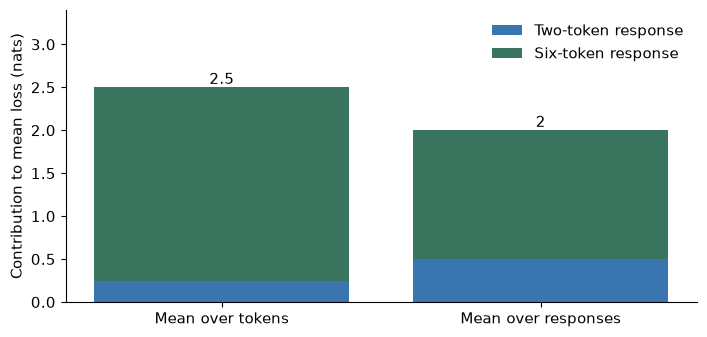

In [11]:
fig, ax = plt.subplots()
short_contributions = [2 / 8, (2 / 2) / 2]
long_contributions = [18 / 8, (18 / 6) / 2]
ax.bar([0, 1], short_contributions, color="#3976AF", label="Two-token response")
ax.bar([0, 1], long_contributions, bottom=short_contributions,
       color="#39745E", label="Six-token response")
for i, total in enumerate([2.5, 2.]):
    ax.text(i, total + .04, f"{total:g}", ha="center")
ax.set(xticks=[0, 1], xticklabels=["Mean over tokens", "Mean over responses"],
       ylabel="Contribution to mean loss (nats)", ylim=(0, 3.4))
ax.legend(loc="upper right", frameon=False)
fig.tight_layout()
plt.show()

Under the token mean, the long response has six of eight token slots; the
short one has two. Under the response mean, each response's own mean gets
weight one half. The tall green segment also reflects its larger loss per
token. A reported loss is meaningful only with its target mask and reduction.

## 8. Inspect a fresh adapter

Imagine adding a second path to an existing four-input, three-output
linear layer. The original path keeps its weight and bias. The new
path first compresses the input from four features to two, then
expands it to three. This is low-rank adaptation, or LoRA. A fresh
adapter is built so this second path starts by adding zero.

Write the base weight as $W_0$, its bias as $\mathbf b_0$, and the
two LoRA factors as $A$ and $B$. The rank setting is $r=2$ and the
scale is $\alpha/r=4/2=2$. Using column vectors, the computation is

$$
\mathbf y
= W_0\mathbf x+\mathbf b_0+2B(A\mathbf x).
$$

The factor $A$ has shape $[2,4]$, so $A\mathbf x$ has two entries.
The factor $B$ has shape $[3,2]$, so the update has three entries
and can be added to the base output. The implementation initializes
$A$ randomly and $B$ to zero. Consequently the update is the zero
vector even if $A\mathbf x$ contains nonzero entries. The base bias
still contributes to the output.

Create the input with `base.weight.new_tensor` so its dtype and
device match the layer. This run uses CPU float64. The seed fixes
the illustrative parameter values and the numeric output. The
equality at initialization follows from $B=0$ for any base
initialization.

In [12]:
from examples.ch16_adaptation.model import LoRALinear

with torch.random.fork_rng(devices=[]):
    torch.manual_seed(1607)
    base = torch.nn.Linear(4, 3, bias=True, dtype=torch.float64)
    adapter = LoRALinear(base, rank=2, alpha=4)

lora_x = base.weight.new_tensor([1, 0, 0, 1])
with torch.no_grad():
    lora_base_output = base(lora_x)
    lora_output = adapter(lora_x)
    lora_update = adapter.scale * (
        adapter.b @ (adapter.a @ lora_x)
    )

assert adapter.scale == 2.0
assert torch.count_nonzero(adapter.b) == 0
torch.testing.assert_close(
    lora_update, torch.zeros_like(lora_update), rtol=0, atol=0
)
torch.testing.assert_close(
    lora_output, lora_base_output, rtol=0, atol=0
)

print("Adapter scale", adapter.scale)
print("Base output   ", [f"{v:.12f}" for v in lora_base_output])
print("Wrapped output", [f"{v:.12f}" for v in lora_output])
print("Adapter update", lora_update.tolist())

Adapter scale 2.0
Base output    ['-0.006492101944', '0.270685236461', '-0.654326084645']
Wrapped output ['-0.006492101944', '0.270685236461', '-0.654326084645']
Adapter update [0.0, 0.0, 0.0]


Inspect all four parameter tensors. A `requires_grad` flag of
`True` makes a parameter eligible to receive gradients. This
wrapper sets the base flags to `False` and leaves both factors
trainable.

| Parameter | Shape | Number of scalars | Trainable |
| :-- | :-- | --: | :-- |
| Base weight $W_0$ | $[3,4]$ | 12 | No |
| Base bias $\mathbf b_0$ | $[3]$ | 3 | No |
| Factor $A$ | $[2,4]$ | 8 | Yes |
| Factor $B$ | $[3,2]$ | 6 | Yes |

There are $2\cdot4+3\cdot2=14$ trainable scalars and $15+14=29$
scalars in the wrapper altogether. The zero-initialized factor
still counts as trainable. Its stored values are zero now, while
its gradient flag permits an optimizer to change them.

In [13]:
expected_lora = {
    "base.weight": ((3, 4), False),
    "base.bias": ((3,), False),
    "a": ((2, 4), True),
    "b": ((3, 2), True),
}
print(f"{'Parameter':<13} {'Shape':<8} {'Scalars':>7}  Grad flag")
for name, parameter in adapter.named_parameters():
    shape = tuple(parameter.shape)
    assert (shape, parameter.requires_grad) == expected_lora[name]
    print(
        f"{name:<13} {str(shape):<8} {parameter.numel():>7}  "
        f"{parameter.requires_grad}"
    )
lora_trainable = sum(
    p.numel() for p in adapter.parameters() if p.requires_grad
)
lora_total = sum(p.numel() for p in adapter.parameters())
assert lora_trainable == 14 and lora_total == 29
print(f"Trainable {lora_trainable} of {lora_total}")

Parameter     Shape    Scalars  Grad flag
a             (2, 4)         8  True
b             (3, 2)         6  True
base.weight   (3, 4)        12  False
base.bias     (3,)           3  False
Trainable 14 of 29


The scalar extension shows how learning starts. With $y=2+4ba$ and
$L=y^2/2$, the gradients are $\partial L/\partial b=4ya$ and
$\partial L/\partial a=4yb$. Initially $a=1$, $b=0$, so $y=2$,
$\partial L/\partial b=8$, and $\partial L/\partial a=0$.
One SGD step of size 0.1 gives $b=-0.8$ and $a=1$. Now $y=-1.2$,
the loss is 0.72, and the gradients are $-4.8$ for $b$ and $3.84$ for $a$.

If both factors start at zero, the output still equals the base output, but
both factor gradients are zero. Ordinary SGD cannot start changing this
branch. A zero initial *update* is useful; zeroing every factor is not.

In [14]:
scalar_a = torch.tensor(1., dtype=torch.float64, requires_grad=True)
scalar_b = torch.tensor(0., dtype=torch.float64, requires_grad=True)
def scalar_lora(a, b):
    return 2 + 4 * b * a
scalar_y = scalar_lora(scalar_a, scalar_b)
(scalar_y.square() / 2).backward()
assert scalar_a.grad.item() == 0 and scalar_b.grad.item() == 8
print("Initial: y =", scalar_y.item(), "grad a =", scalar_a.grad.item(),
      "grad b =", scalar_b.grad.item())
with torch.no_grad():
    scalar_a -= .1 * scalar_a.grad
    scalar_b -= .1 * scalar_b.grad
scalar_a.grad = scalar_b.grad = None
scalar_y = scalar_lora(scalar_a, scalar_b)
(scalar_y.square() / 2).backward()
np.testing.assert_allclose([scalar_y.item(), scalar_a.grad.item(), scalar_b.grad.item()],
                           [-1.2, 3.84, -4.8], rtol=0, atol=1e-12)
print("After step: y =", round(scalar_y.item(), 2),
      "grad a =", round(scalar_a.grad.item(), 2),
      "grad b =", round(scalar_b.grad.item(), 2))

Initial: y = 2.0 grad a = 0.0 grad b = 8.0
After step: y = -1.2 grad a = 3.84 grad b = -4.8


In [15]:
zero_a = torch.tensor(0., dtype=torch.float64, requires_grad=True)
zero_b = torch.tensor(0., dtype=torch.float64, requires_grad=True)
(scalar_lora(zero_a, zero_b).square() / 2).backward()
assert zero_a.grad.item() == zero_b.grad.item() == 0
print("Both factors zero: both gradients zero.")

Both factors zero: both gradients zero.


## 9. Compare trainable weights

Train two versions of the same small classifier on the same eight
examples. The frozen version lets only the task head change. The
full version also lets the encoder learn. For each version, run
one experiment with one optimizer step and a separate experiment
with two. In particular, the two-step run starts over and does
not resume from a trained model.

Save a snapshot of one untouched `TinyClassifier` and load it
into four fresh instances. All four therefore start with the
same encoder and the same zero head. Use only the first two
outputs of `classification_data`, the training inputs and class
labels. The helper trains with full-batch SGD, meaning one update
uses all eight examples, and we give it the same learning rate
of 0.2 in every run. Holding these choices fixed means that the
encoder's trainable status and the number of updates are the
only differences in the comparison.

In [16]:
from examples.ch16_adaptation.model import (
    TinyClassifier, train_classifier,
)
from examples.ch16_adaptation.run_examples import classification_data

train_x, train_y = classification_data()[:2]
classifier_start = {
    name: tensor.detach().clone()
    for name, tensor in TinyClassifier().state_dict().items()
}
classifier_lr = 0.2
classifier_runs = {}
for steps in (1, 2):
    for mode in ("frozen", "full"):
        fresh = TinyClassifier()
        fresh.load_state_dict(classifier_start)
        train_classifier(
            fresh, train_x, train_y,
            freeze_encoder=(mode == "frozen"),
            steps=steps, lr=classifier_lr,
        )
        classifier_runs[steps, mode] = fresh

print(f"Training features {tuple(train_x.shape)} {train_x.dtype}")
print("Training class counts", train_y.bincount().tolist())

Training features (8, 2) torch.float64
Training class counts [4, 4]


For each weight and bias tensor, subtract its original value and
take the largest absolute entry in that difference. A zero means
the whole tensor is unchanged. Float64 comparisons use absolute
tolerance $10^{-12}$ and zero relative tolerance. The results
distinguish changes from numerical residue in the bias entries.

In [17]:
classifier_atol = 1e-12
classifier_deltas = {
    key: {
        name: (p.detach() - classifier_start[name]).abs().max().item()
        for name, p in model.named_parameters()
    }
    for key, model in classifier_runs.items()
}
print("Steps  Mode    Encoder W   Encoder b   Head W      Head b")
for (steps, mode), changes in classifier_deltas.items():
    values = "   ".join(f"{change:.3e}" for change in changes.values())
    print(f"{steps:>5}  {mode:<6}  {values}")

for (steps, mode), changes in classifier_deltas.items():
    if steps == 1 or mode == "frozen":
        assert changes["encoder.weight"] <= classifier_atol
    else:
        assert changes["encoder.weight"] > classifier_atol
    assert changes["encoder.bias"] <= classifier_atol
    assert changes["head.weight"] > classifier_atol
    assert changes["head.bias"] <= classifier_atol

for steps in (1, 2):
    frozen = classifier_runs[steps, "frozen"]
    full = classifier_runs[steps, "full"]
    assert frozen.encoder.weight.grad is None
    assert full.encoder.weight.grad is not None
    for frozen_p, full_p in zip(
        frozen.head.parameters(), full.head.parameters()
    ):
        torch.testing.assert_close(
            frozen_p, full_p, rtol=0, atol=classifier_atol
        )
assert torch.count_nonzero(
    classifier_runs[1, "full"].encoder.weight.grad
) == 0

Steps  Mode    Encoder W   Encoder b   Head W      Head b
    1  frozen  0.000e+00   0.000e+00   8.237e-02   0.000e+00
    1  full    0.000e+00   0.000e+00   8.237e-02   0.000e+00
    2  frozen  0.000e+00   0.000e+00   1.568e-01   2.776e-18
    2  full    8.305e-03   3.469e-19   1.568e-01   2.776e-18


Why do both encoders stay put on step 1? Let
$\mathbf a_i=E\mathbf x_i+\mathbf c$ be the encoder's pre-activation
vector and $\mathbf h_i=\tanh(\mathbf a_i)$ its feature vector
for example $i$. The head weight $H$ and bias $\mathbf b$ give
logits $\mathbf z_i=H\mathbf h_i+\mathbf b$. Let $\mathbf g_i$
be the cross-entropy gradient for example $i$ with respect to
its logits before batch averaging. The gradient components
are the predicted probabilities minus the one-hot target.

At initialization, every logit is zero. The two predicted
probabilities are both $1/2$, so the target class has gradient
$-1/2$ and the other class has gradient $1/2$. These nonzero
gradients reach the head weight, even though its entries are
currently zero. For a batch of $m$ inputs the weight gradient is
an average of outer products,

$$
\nabla_H L=\frac1m\sum_{i=1}^m\mathbf g_i\mathbf h_i^\top.
$$

The encoder receives a different gradient. Backpropagation
multiplies the head's logit gradient by the transpose of its
weight, then applies the elementwise derivative of $\tanh$.
With $\odot$ denoting elementwise multiplication, the gradient
of the mean loss at the encoder pre-activation is

$$
\nabla_{\mathbf a_i} L
=\frac{1}{m}(H^\top\mathbf g_i)
  \odot(1-\mathbf h_i^2).
$$

At the first backward pass $H=0$, so the encoder gradient
vanishes even in the full run, where those weights have
`requires_grad=True`. SGD then updates $H$. On the second
backward pass the nonzero head weight passes a gradient to the
encoder. The full encoder weight changes at that step, and the
frozen encoder remains unchanged. The frozen weight has no
gradient stored, while the trainable encoder's first gradient
is an actual tensor of zeros.

Both head weights agree after one step and after two. At the
start of step 2, the head and encoder still have the same
values in both runs. The head's gradient is therefore the same
in that backward pass, before the optimizer changes the full
encoder. If training continues, later head updates can differ
because the encoders now supply different features.

The first head-bias gradient sums to zero because the labels
are balanced and the initial predictions are uniform. The
tiny bias differences in the second-step runs are at the
scale of floating-point rounding in this symmetric example.
Comparing the weight tensors separately avoids mistaking
those tiny entries for substantial changes.

An independent calculation from these matrix products reproduces the
step-1 head update and step-2 encoder update without calling backward.
After one step, both encoder weights are unchanged and the largest head
weight change is about 0.08237. After two steps, the largest head change
is about 0.1568 in both runs. The frozen encoder remains unchanged;
the full encoder's largest weight change is 0.008305283. The bias changes
are below the stated tolerance in this symmetric example.

In [18]:
targets_one_hot = torch.nn.functional.one_hot(
    train_y, num_classes=2
).to(dtype=train_x.dtype)
encoder_w0 = classifier_start["encoder.weight"]
encoder_b0 = classifier_start["encoder.bias"]
head_w0 = classifier_start["head.weight"]
head_b0 = classifier_start["head.bias"]
hidden0 = (train_x @ encoder_w0.T + encoder_b0).tanh()
batch_size = train_x.shape[0]

logits0 = hidden0 @ head_w0.T + head_b0
residual0 = logits0.softmax(dim=-1) - targets_one_hot
head_grad0 = residual0.T @ hidden0 / batch_size
head_w1 = head_w0 - classifier_lr * head_grad0
head_b1 = head_b0 - classifier_lr * residual0.mean(dim=0)

logits1 = hidden0 @ head_w1.T + head_b1
residual1 = logits1.softmax(dim=-1) - targets_one_hot
preact_grad1 = (residual1 @ head_w1) * (1 - hidden0.square())
encoder_grad1 = preact_grad1.T @ train_x / batch_size
encoder_w2 = encoder_w0 - classifier_lr * encoder_grad1

torch.testing.assert_close(
    head_w1, classifier_runs[1, "full"].head.weight,
    rtol=0, atol=classifier_atol,
)
torch.testing.assert_close(
    encoder_w2, classifier_runs[2, "full"].encoder.weight,
    rtol=0, atol=classifier_atol,
)
expected_change = (encoder_w2 - encoder_w0).abs().max().item()
print(f"Manual step-2 encoder weight change {expected_change:.9f}")

Manual step-2 encoder weight change 0.008305283


Now isolate a different issue: a frozen operation between a trainable
parameter and the loss. Set $h=ux$, $y=3h$, and $L=y^2/2$, with $u=1$,
$x=2$. The multiplier has no trainable gradient, but the gradient reaching
$u$ is $y\cdot3x=36$. A frozen weight remains part of the chain rule.

Placing the multiplication inside `no_grad` gives an output with no tracked
connection to $u$. Here the resulting loss cannot call backward at all;
in a larger model with a later trainable head, that head could still train
while the path to $u$ would remain broken. `eval()` is different again: it
selects evaluation behavior of modules, without globally disabling autograd.

In [19]:
upstream = torch.tensor(1., dtype=torch.float64, requires_grad=True)
frozen_multiplier = torch.tensor(3., dtype=torch.float64)
frozen_output = frozen_multiplier * (upstream * 2)
(frozen_output.square() / 2).backward()
assert upstream.grad.item() == 36 and frozen_multiplier.grad is None
with torch.no_grad():
    detached_output = frozen_multiplier * (upstream * 2)
assert not detached_output.requires_grad
print("Gradient through frozen operation:", upstream.grad.item())
print("Frozen multiplier gradient:", frozen_multiplier.grad)
print("Output inside no_grad tracks a gradient:", detached_output.requires_grad)

Gradient through frozen operation: 36.0
Frozen multiplier gradient: None
Output inside no_grad tracks a gradient: False


## 10. Keep the reference fixed (optional)

Direct Preference Optimization (DPO) compares the policy's
preference for a chosen response over a rejected response
with the preference already expressed by a reference model.
The policy gap is $-2-(-3.5)=1.5$. The reference gap is
$-3-(-3.25)=0.25$. With $\beta=1$ the margin is

$$
m = \beta\big[(p_c-p_r)-(r_c-r_r)\big] = 1.25.
$$

Here $p_c,p_r$ denote policy log-probabilities and $r_c,r_r$
denote reference log-probabilities. For one pair the loss is
$L=-\ln\sigma(m)=\ln(1+\exp(-m))$, where
$\sigma(z)=1/(1+\exp(-z))$. Its derivative with respect
to the margin is

$$
\frac{dL}{dm}=-\frac{1}{1+\exp(m)}=-\sigma(-m).
$$

The policy scores enter the margin with derivatives $+\beta$
for the chosen response and $-\beta$ for the rejected response.
Their loss gradients are therefore $-\beta\sigma(-m)$ and
$+\beta\sigma(-m)$. If the scores could be updated directly,
gradient descent would raise the chosen score and lower the
rejected one. In a model these gradients flow through the
response log-probabilities to shared trainable weights.

In the code, the reference scores are detached before their
difference is computed. They supply the value $0.25$ for the
forward pass, while autograd has no path from the loss back to
their original tensors. Give all four tensors
`requires_grad=True` so the test distinguishes detachment
from simply starting with gradients disabled.

In [20]:
from examples.ch16_adaptation.model import dpo_loss

dpo_names = ("policy chosen", "policy rejected",
             "reference chosen", "reference rejected")
dpo_scores = tuple(
    torch.tensor(x, dtype=torch.float64, requires_grad=True)
    for x in (-2.0, -3.5, -3.0, -3.25)
)
dpo_value = dpo_loss(*dpo_scores, beta=1)
dpo_value.backward()

print(f"Loss: {dpo_value.item():.12f}")
for name, score in zip(dpo_names, dpo_scores):
    grad = "None" if score.grad is None else f"{score.grad.item():+.12f}"
    print(f"{name:<19} requires_grad={score.requires_grad}  grad={grad}")

Loss: 0.251929081345
policy chosen       requires_grad=True  grad=-0.222700138825
policy rejected     requires_grad=True  grad=+0.222700138825
reference chosen    requires_grad=True  grad=None
reference rejected  requires_grad=True  grad=None


In [21]:
dpo_expected_margin = 1.5 - 0.25
dpo_expected_grad = 1.0 / (1.0 + np.exp(dpo_expected_margin))
torch.testing.assert_close(
    dpo_value,
    dpo_value.new_tensor(np.logaddexp(0.0, -dpo_expected_margin)),
    rtol=0, atol=1e-12,
)
for score, sign in zip(dpo_scores[:2], (-1, 1)):
    torch.testing.assert_close(
        score.grad, score.new_tensor(sign * dpo_expected_grad),
        rtol=0, atol=1e-12,
    )
assert all(score.requires_grad for score in dpo_scores)
assert all(score.grad is None for score in dpo_scores[2:])
print("Loss and policy gradients match the scalar derivation.")
print("Both reference gradients are None.")

Loss and policy gradients match the scalar derivation.
Both reference gradients are None.


Both reference gradient fields stay `None`. In this fresh
backward pass, `None` means no gradient was accumulated for
that tensor. A gradient tensor containing zero would instead
represent a computed value. Detachment affects this loss's
graph without changing the original reference tensors'
`requires_grad` flags.

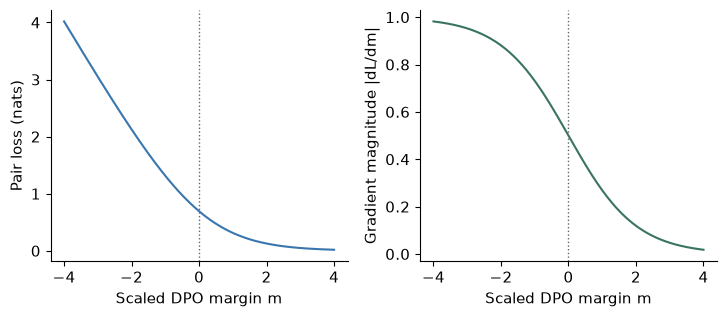

In [22]:
margins = np.linspace(-4, 4, 161)
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.3))
axes[0].plot(margins, np.logaddexp(0., -margins), color="#3976AF")
axes[1].plot(margins, 1 / (1 + np.exp(margins)), color="#39745E")
for ax in axes:
    ax.set_xlabel("Scaled DPO margin m")
    ax.axvline(0, color="#596772", linestyle=":", linewidth=1)
axes[0].set_ylabel("Pair loss (nats)")
axes[1].set_ylabel("Gradient magnitude |dL/dm|")
fig.tight_layout()
plt.show()

The loss decreases as the relative margin increases. A poorly ranked
pair supplies a larger gradient with respect to that margin. The plot is
the scalar loss function, not measured model performance. When gradients
flow into shared weights, different pairs and tokens can interact.

## 11. Rebuild an adapted model (optional)

Save both factors $A$ and $B$ for every adapted query and value projection,
plus the new classifier's weight and bias. Identify each factor by its full
module path and record its shape, orientation, rank, alpha, and scaling rule.
Include any other trained biases or modules. Save the immutable base revision
and configuration, tokenizer and its revision, special-token IDs, prompt
format, label order, pooling rule, storage dtype, and evaluation settings.
An adapter trained for one base is not a self-contained replacement for it.

For a training restart, additionally save optimizer and scheduler state,
training progress, random-generator states and the data position. These
restart states are distinct from the inference checkpoint.

For a two-input affine layer, test zero, $(1,0)^\top$, and $(0,1)^\top$.
The zero input gives the bias. Subtracting that result from each unit-vector
output gives the corresponding matrix column. Together these probes check
the full affine map. The example below restores factors onto a known base
and compares the separated and merged paths, including the base bias.

In [23]:
from copy import deepcopy
from io import BytesIO

checkpoint_base = nn.Linear(2, 2, bias=True, dtype=torch.float64)
with torch.no_grad():
    checkpoint_base.weight.copy_(torch.tensor([[1., 2.], [0., -1.]]))
    checkpoint_base.bias.copy_(torch.tensor([.25, -.5]))
checkpoint_layer = LoRALinear(deepcopy(checkpoint_base), rank=1, alpha=2)
with torch.no_grad():
    checkpoint_layer.a.copy_(torch.tensor([[1., -1.]]))
    checkpoint_layer.b.copy_(torch.tensor([[.5], [1.]]))
buffer = BytesIO()
torch.save({"rank": 1, "alpha": 2., "base_revision": "fixed-toy-base-v1",
            "a": checkpoint_layer.a.detach(), "b": checkpoint_layer.b.detach()}, buffer)
buffer.seek(0)
saved = torch.load(buffer, map_location="cpu", weights_only=True)
assert saved["base_revision"] == "fixed-toy-base-v1"
restored = LoRALinear(deepcopy(checkpoint_base), saved["rank"], saved["alpha"])
with torch.no_grad():
    restored.a.copy_(saved["a"])
    restored.b.copy_(saved["b"])
probes = torch.tensor([[0., 0.], [1., 0.], [0., 1.]], dtype=torch.float64)
with torch.no_grad():
    wanted = checkpoint_layer(probes)
    reloaded = restored(probes)
    merged = F.linear(probes, restored.merged_weight(), restored.base.bias)
torch.testing.assert_close(reloaded, wanted, rtol=0, atol=1e-12)
torch.testing.assert_close(merged, wanted, rtol=0, atol=1e-12)
print("Zero and coordinate-probe outputs:\n", wanted.numpy())
print("Restored and merged paths agree on all three probes.")

Zero and coordinate-probe outputs:
 [[ 0.25 -0.5 ]
 [ 2.25  1.5 ]
 [ 1.25 -3.5 ]]
Restored and merged paths agree on all three probes.


The numerical fixture uses $W_0=\left[\begin{smallmatrix}1&2\\0&-1\end{smallmatrix}\right]$,
$A=(1,-1)$, $B=(0.5,1)^\top$, scale 2, and base bias $(0.25,-0.5)^\top$.
The merged matrix is $\left[\begin{smallmatrix}2&1\\2&-3\end{smallmatrix}\right]$.
The zero, first-coordinate and second-coordinate probes respectively produce
$(0.25,-0.5)$, $(2.25,1.5)$ and $(1.25,-3.5)$. Both the restored-factor
calculation and the merged layer match all three outputs to absolute
tolerance $10^{-12}$.

One probe can miss a nonzero error. Add
$D=\left[\begin{smallmatrix}1&-1\\0&0\end{smallmatrix}\right]$ to a
weight matrix. The error vanishes on input $(1,1)^\top$, since $D(1,1)^\top=0$.
Both coordinate probes detect it. This also explains why an input that barely
activates a swapped projection might fail to expose a loading mistake.

In [24]:
with torch.no_grad():
    wrong_weight = restored.merged_weight() + torch.tensor(
        [[1., -1.], [0., 0.]], dtype=torch.float64)
    lone_input = torch.ones((1, 2), dtype=torch.float64)
    one_right = restored(lone_input)
    one_wrong = F.linear(lone_input, wrong_weight, restored.base.bias)
    wrong_probes = F.linear(probes, wrong_weight, restored.base.bias)
torch.testing.assert_close(one_wrong, one_right, rtol=0, atol=1e-12)
assert not torch.allclose(wrong_probes, wanted)
print("One probe missed the wrong matrix:", one_wrong.tolist())
print("Coordinate-probe errors:\n", (wrong_probes - wanted).numpy())

One probe missed the wrong matrix: [[3.25, -1.5]]
Coordinate-probe errors:
 [[ 0.  0.]
 [ 1.  0.]
 [-1.  0.]]


A query and a value projection can have identical shapes, so check their
names and their numerical effects separately. Use a probe that activates
each saved adapter. Here both adapters have rank one and scale two, but
at the first coordinate input their corrections are $(1,2)^\top$ for query
and $(2,-1)^\top$ for value. Swapping the factors produces a visible mismatch.
The adapted-minus-base difference cancels the base term: correct adapter
corrections alone therefore cannot verify the base checkpoint.

In [25]:
query_a = torch.tensor([[1., -1.]], dtype=torch.float64)
query_b = torch.tensor([[.5], [1.]], dtype=torch.float64)
value_a = torch.tensor([[1., 1.]], dtype=torch.float64)
value_b = torch.tensor([[1.], [-.5]], dtype=torch.float64)
probe = torch.tensor([1., 0.], dtype=torch.float64)
query_correction = 2 * query_b @ (query_a @ probe)
value_correction = 2 * value_b @ (value_a @ probe)
torch.testing.assert_close(query_correction, probe.new_tensor([1., 2.]))
torch.testing.assert_close(value_correction, probe.new_tensor([2., -1.]))
assert not torch.allclose(query_correction, value_correction)
print("Query correction:", query_correction.tolist())
print("Value correction:", value_correction.tolist())
print("Swapping these same-shaped factors fails the named-projection checks.")

Query correction: [1.0, 2.0]
Value correction: [2.0, -1.0]
Swapping these same-shaped factors fails the named-projection checks.


For the complete attention model, check base identifiers, exact projection
names and shapes before loading. Compare saved pre-reload logits with
post-reload logits on a varied fixed batch, using the same tokenizer,
formatting, padding, label order, dtype and evaluation mode. Include inputs
of different lengths and examples that exercise each class. Check each
adapted projection's intermediate output when diagnosing a mismatch.

Use tolerances appropriate to precision and quantization. Finite output
checks are evidence of agreement on those inputs; they do not prove that
two nonlinear models agree on every input. Configuration and identity
checks remain necessary even if a small batch passes.

## 12. Plan an adaptation comparison (optional)

Give all three systems the same encoder architecture, tokenizer, pooling
rule, and two-class head returning `LOOKUP` or `UPDATE`. Use the same
pretrained base revision and same initial head within each paired run.
The conditions are: head only; full base and head; and LoRA on declared
projections plus the head. One explicit starting configuration is rank four,
alpha eight, and adapters on every query and value projection. Their zero
initial update preserves the initial encoder function. Record dropout behavior
and keep it consistent where the comparison requires the same stochastic model. Also report the unchanged pretrained classifier
when one exists, or a clearly specified zero-training prompting baseline
with its different output interface reported separately. A majority-class
baseline provides an additional task-level reference.

Group messages by their generating template and customer before splitting.
If those grouping relationships overlap, keep the connected families
together. Split groups into training, validation and final test sets; keep
paraphrases and near-duplicates in the same split. If deployment is meant
to generalize to later time periods or new customers, reflect that in the
split. Check for duplicates before tuning any configuration.

Keep data, labels, preprocessing and evaluation fixed. Give each method a
declared tuning budget and use validation data to select learning rate,
rank and stopping time. Repeating the same learning rate for every method
is a controlled diagnostic, but may not compare each method fairly at its
best setting. Report the selected configuration, examples seen and compute
used. Repeat over several predetermined seeds, pairing initial heads and
data order across methods when possible. Report per-run results and spread,
and use the test set only for the final comparison. Check that each split
contains both classes. Include contrastive phrasings such as asking to confirm
the new address versus asking to change to it, so that the words "new address"
do not uniquely identify a class. If estimating sampling uncertainty, resample
whole test families to preserve their within-group dependence.

Measure test accuracy, the confusion matrix, and per-class precision and
recall. Inspect errors on unfamiliar phrasings. If preserving earlier skills
matters, evaluate those too. For a generated-label baseline, separately
measure valid output format and correct labels under the same parsing rule.
Do not count malformed outputs as correct without disclosing that rule.

Report trainable and total parameter counts, per-task checkpoint bytes,
and the base storage required to use each checkpoint. Measure peak training
memory and elapsed time on specified hardware with the same precision,
batch size and sequence lengths. Parameter counts alone do not determine
activation memory, optimizer state, runtime or measured accuracy. State whether
the deployed adapter is merged: merging removes the separate factor tensors
from the deployed linear layers. Distinguish raw tensor payload from actual
file size, which also depends on metadata and compression.

For a concrete storage calculation, suppose the 120-parameter encoder
contains one selected $6\times6$ matrix and uses the three-class head from
Exercise 1. A rank-two adapter adds $2(6+6)=24$ scalars. The following counts
exclude file-format metadata and use four bytes per scalar. This is a
counting illustration, separate from the two-class address experiment.

| Method | Trainable scalars | Total resident scalars | Per-task weight bytes |
| :-- | --: | --: | --: |
| Head only | 21 | 141 | 84 |
| Full fine-tuning | 141 | 141 | 564 |
| LoRA plus head | 45 | 165 | 180 |

Head and adapter checkpoints both need the original 120-scalar base,
which takes another 480 payload bytes if stored in float32. The full
checkpoint already contains its updated base. Adam state or mixed-precision
copies would add training storage; those are not included in this table.
No accuracy ranking follows from these counts.

In [26]:
storage_rows = {
    "Head only": (21, 141, 21 * 4),
    "Full fine-tuning": (141, 141, 141 * 4),
    "LoRA plus head": (21 + 2 * (6 + 6), 141 + 24, (21 + 24) * 4),
}
assert storage_rows["LoRA plus head"] == (45, 165, 180)
for method, (trainable, total, task_bytes) in storage_rows.items():
    print(f"{method:<18} trainable {trainable:3}  total {total:3}  task bytes {task_bytes:3}")
print("Frozen-base payload for head-only / LoRA:", 120 * 4, "bytes")

Head only          trainable  21  total 141  task bytes  84
Full fine-tuning   trainable 141  total 141  task bytes 564
LoRA plus head     trainable  45  total 165  task bytes 180
Frozen-base payload for head-only / LoRA: 480 bytes
